Weather Prediction Regression Model Comparison:
LinearRegression: MAE=2.02, RMSE=2.60, R2=-5.78
RidgeRegression: MAE=1.84, RMSE=2.24, R2=-4.00
RandomForest: MAE=1.15, RMSE=1.27, R2=-0.61


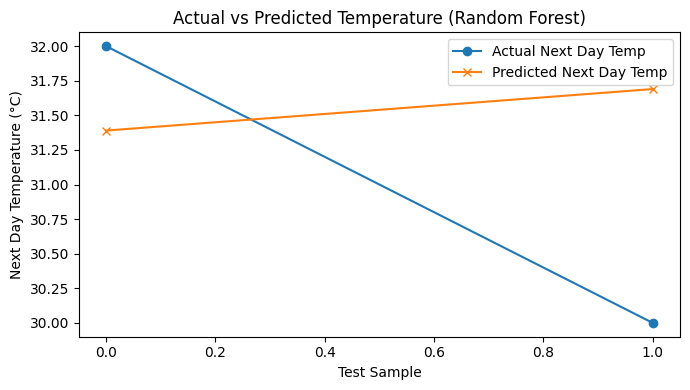

/tmp/ipython-input-1624955026.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_names, y=rf_importances, palette='coolwarm')


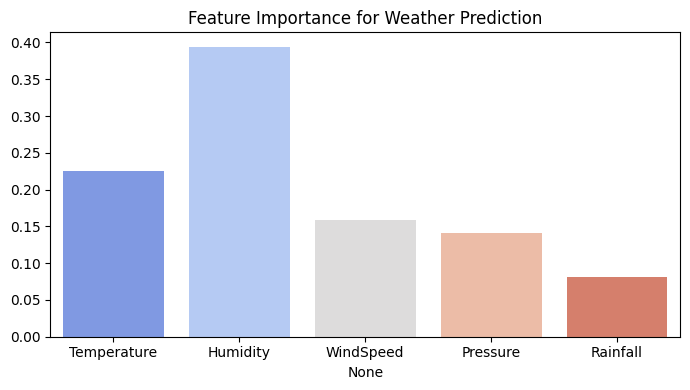


Predicted Next Day Temperature for the sample: 30.88 °C


In [1]:
# Weather Prediction Using Regression (Sample Submission-Ready Code)

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Sample weather data (synthetic, for demo)
data = pd.DataFrame({
    'Temperature': [29, 31, 30, 32, 33, 34, 32, 30, 29, 32],
    'Humidity': [45, 50, 48, 46, 44, 41, 42, 43, 46, 49],
    'WindSpeed': [8, 5, 6, 7, 9, 5, 7, 6, 8, 5],
    'Pressure': [1012, 1011, 1013, 1010, 1012, 1009, 1011, 1012, 1013, 1010],
    'Rainfall': [2, 5, 0, 8, 0, 10, 1, 0, 3, 0],
    'NextDayTemp': [31, 30, 32, 33, 34, 32, 30, 29, 32, 33]
})

# 2. Features and target variable
X = data[['Temperature', 'Humidity', 'WindSpeed', 'Pressure', 'Rainfall']]
y = data['NextDayTemp']

# 3. Preprocessing: Scale features for regression
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Train/test split for model demonstration
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# 5. Model definitions: Linear, Ridge, and Random Forest Regression
models = {
    'LinearRegression': LinearRegression(),
    'RidgeRegression': Ridge(alpha=1.0),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
}
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = {
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred)
    }

# 6. Print evaluation results for all models
print("Weather Prediction Regression Model Comparison:")
for name, metrics in results.items():
    print(f"{name}: MAE={metrics['MAE']:.2f}, RMSE={metrics['RMSE']:.2f}, R2={metrics['R2']:.2f}")

# 7. Visualization: Actual vs Predicted for best model (Random Forest)
rf_model = models['RandomForest']
y_pred_rf = rf_model.predict(X_test)
plt.figure(figsize=(7,4))
plt.plot(y_test.values, label='Actual Next Day Temp', marker='o')
plt.plot(y_pred_rf, label='Predicted Next Day Temp', marker='x')
plt.title('Actual vs Predicted Temperature (Random Forest)')
plt.xlabel('Test Sample')
plt.ylabel('Next Day Temperature (°C)')
plt.legend()
plt.tight_layout()
plt.show()

# 8. Feature Importance Bar Chart (Random Forest)
rf_importances = rf_model.feature_importances_
feature_names = X.columns
plt.figure(figsize=(7,4))
sns.barplot(x=feature_names, y=rf_importances, palette='coolwarm')
plt.title('Feature Importance for Weather Prediction')
plt.tight_layout()
plt.show()

# 9. Predict for a new weather sample
new_sample = pd.DataFrame([{
    'Temperature': 33,
    'Humidity': 43,
    'WindSpeed': 6,
    'Pressure': 1011,
    'Rainfall': 2
}])
new_sample_scaled = scaler.transform(new_sample)
pred_temp = rf_model.predict(new_sample_scaled)[0]
print(f"\nPredicted Next Day Temperature for the sample: {pred_temp:.2f} °C")
